[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AGRIdigital-Climbat/PlantillaMapa/blob/main/05_Sequia/01_sequia.ipynb)

# Sequia: SPI-3, frecuencia y duracion de eventos secos
## PROSUCO - CLIMBAT | Analisis por municipio de Bolivia (GEE + Colab)

> **Area de estudio = tu GeoJSON.** Este notebook usa por defecto:
>
> `RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"` (compartido `Cualquiera con el enlace`).
> El GeoJSON **siempre manda**: al cargarse, `roi`, `ZONA['bbox']`, `ZONA['centro']`
> y `area_km2` se recalculan desde el poligono. El `bbox` de CONFIG solo es respaldo
> si cambias a `AOI_MODE = "bbox"`.

**Orden de ejecucion:** 1) Instalacion -> 2) Autenticacion GEE (`EE_PROJECT`) ->
3) CONFIG (anos + satelite + umbrales) -> 4) AOI desde Drive -> 5) celdas del modulo.
Solo edita la celda **CONFIGURACION MAESTRA**.


In [1]:
# ============================================================
# 1.1 Instalación de librerías (ejecutar una sola vez en Colab)
# ============================================================

import importlib
import subprocess
import sys


def _asegurar(paquete, modulo=None):
    """Instala el paquete solo si no está disponible."""
    try:
        importlib.import_module(modulo or paquete)
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", paquete]
        )


_asegurar("earthengine-api", "ee")
_asegurar("geemap")
_asegurar("geopandas")
_asegurar("pandas")
_asegurar("numpy")
_asegurar("matplotlib")

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

print("Librerías listas.")
print("earthengine-api:", ee.__version__)
print("geemap:", geemap.__version__)

Librerías listas.
earthengine-api: 1.7.39
geemap: 0.38.8


In [2]:
# ============================================================
# 1.2 Autenticación en Google Earth Engine
# ============================================================
# >>> REEMPLAZAR por el id del proyecto de Cloud de PROSUCO/CLIMBAT <<<

EE_PROJECT = "gen-lang-client-0636031685"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

print("Earth Engine inicializado correctamente.")
print("Proyecto:", EE_PROJECT)

Earth Engine inicializado correctamente.
Proyecto: gen-lang-client-0636031685


## Configuración maestra

> **✏️ Esta es la única celda que se edita para diagnosticar una zona nueva.**

| Bloque | Qué define | Verificación previa |
|---|---|---|
| `ZONA` | nombre, bbox `[oeste, sur, este, norte]` y punto de vista | dibujar en [geojson.io](https://geojson.io) o en el editor GEE y copiar coordenadas |
| `AOI_MODE`/`RUTA_AOI` | fuente del AOI: `"bbox"` o `"auto"` (polígono **GeoJSON**) | exportar el polígono desde QGIS como **GeoJSON**; en `RUTA_AOI` se puede pegar un **enlace de Google Drive** (el notebook lo descarga solo) o una ruta de Drive |
| `PUNTOS_LOCALES` | manantiales/bofedales del saber local | levantamiento con las comunidades |
| `FECHA_INICIO / FECHA_FIN` | ventana analítica (**30+ años**) | default 1996-01-01 → 2026-12-31 |
| `CALENDARIO` | meses de siembra/cosecha y estación seca | observadores Yapuchiri |
| `UMBRALES` | todos los cortes analíticos en un solo lugar | criterio técnico + experiencia local |
| `ESCALAS` | resolución de cómputo (m); subir si la zona es grande | — |

In [3]:
# ===========================================================================
# CONFIGURACIÓN MAESTRA — ÚNICA CELDA QUE SE EDITA PARA CADA ZONA
# ===========================================================================

# --- 1. Zona de intervención ------------------------------------------------
# Fuente del AOI:
#   "bbox" -> usa el rectángulo ZONA["bbox"] de abajo (rápido, sin Drive)
#   "auto" -> usa un polígono .geojson. RUTA_AOI admite 3 formas:
#       * Enlace o ID de Google Drive  -> se DESCARGA solo (no subes nada a mano)
#           "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"
#           "11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N"
#       * Ruta en tu Drive ya montado  -> se lee directo, SIN copiar a /content
#           "/content/drive/MyDrive/CLIMBAT/zona.geojson"
#       * Carpeta en Drive             -> toma el único .geojson que contenga
#           "/content/drive/MyDrive/CLIMBAT"
AOI_MODE = "auto"
RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"

ZONA = {
    # Coordenadas geocodificadas: Escoma (La Paz, Bolivia) ~3832 msnm
    # (solo se usan como respaldo cuando AOI_MODE = "bbox")
    "nombre": "Escoma, La Paz (prueba)",
    "bbox": [-69.33, -15.86, -68.93, -15.46],   # [oeste, sur, este, norte]
    "centro": [-69.1289, -15.6615],             # punto de vista del mapa
    "zoom": 10,
}

# --- 2. Puntos levantados con comunidades (saber local) ---------------------
# Listas de [longitud, latitud]. Dejar vacías si aún no hay levantamiento.
PUNTOS_LOCALES = {
    "manantiales": [],
    "bofedales": [],
}

# --- 3. Ventana analítica: 30+ años hacia atrás desde el año actual ---------
# Regla de la plantilla: 1996-01-01 -> 2026-12-31 (todo análisis de rango de años usa esta).
# Los datasets usan su período nativo si es mayor: CHIRPS 1981+ · ERA5-Land 1950+
# · JRC 1984–2021 · MODIS 2000+ (NDVI) / 2001+ (MCD12Q1 agricultura) · SMAP 2015+
FECHA_INICIO = "1996-01-01"
FECHA_FIN = "2026-12-31"

# --- 4. Calendario agrícola local (verificar con observadores Yapuchiri) ----
CALENDARIO = {
    "siembra": 11,       # mes de siembra (1–12)
    "cosecha": 4,        # mes de cosecha (1–12)
    "meses_estacion_seca": [5, 6, 7, 8, 9, 10],   # se usa en M10 (bofedales)
}

# --- 5. Umbrales analíticos (ajustar con criterio técnico y local) ----------
UMBRALES = {
    "helada_c": 0.0,               # °C mínima para contar un día de helada (M4)
    "helada_grave_c": -2.0,        # °C de helada grave (daño severo) (M4)
    "mes_seco_mm": 30.0,           # mm/mes para clasificar mes seco (M2)
    "spi_severo": -1.5,            # umbral de sequía severa SPI-3 (M5)
    "ndvi_anomalia_z": -1.5,       # anomalía NDVI severa (M7)
    "manantial_occurrencia": 100,  # % ocurrencia JRC mínima (M9)
    "manantial_drenaje_max": 50,   # celdas acumuladas máx. (cabeceras) (M9)
    "bofedal_altitud_min": 3000,   # msnm mínimo (M10)
    "bofedal_altitud_max": 5200,   # msnm máximo (M10)
    "bofedal_pendiente_max": 5.0,  # grados de pendiente máxima (M10)
    "bofedal_seasonality": 8,      # meses con agua JRC mínimos (M10)
    "bofedal_ndvi_seco": 0.25,     # NDVI mínimo en estación seca (M10)
    "clases_agricolas": [12, 14],  # LC_Type1 MCD12Q1: 12=cultivos, 14=mosaico (M11)
}

# --- 6. Escalas de cómputo (metros) -----------------------------------------
# Subir si la zona es muy grande (más rápido, menos detalle)
ESCALAS = {"clima": 5000, "modis": 250, "jrc": 90, "detalle": 30}
TILE_SCALE = 4

# ===========================================================================
# A partir de aquí no se edita nada
# ===========================================================================

MESES = list(range(1, 13))
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
            "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

roi = None   # se construye en la celda 1.4 (bbox o GeoJSON según AOI_MODE)
centro = None
ANIO_INI = int(FECHA_INICIO[:4])
ANIO_FIN = int(FECHA_FIN[:4])

# Años COMPLETOS (se excluye el año en curso de métricas y mapas anuales)
ANIOS_COMPLETOS = list(range(ANIO_INI, ANIO_FIN))
FILTRO_ANIOS_COMPLETOS = ee.Filter.calendarRange(
    ANIOS_COMPLETOS[0], ANIOS_COMPLETOS[-1], "year"
)

print("Zona:", ZONA["nombre"])
print("Ventana analítica:", FECHA_INICIO, "->", FECHA_FIN,
      f"({ANIO_FIN - ANIO_INI + 1} años calendario)")
print("Años completos para métricas:", ANIOS_COMPLETOS[0], "-", ANIOS_COMPLETOS[-1])
print("Calendario: siembra mes", CALENDARIO["siembra"],
      "| cosecha mes", CALENDARIO["cosecha"])
print("Umbrales activos:", UMBRALES)

Zona: Escoma, La Paz (prueba)
Ventana analítica: 1996-01-01 -> 2026-12-31 (31 años calendario)
Años completos para métricas: 1996 - 2025
Calendario: siembra mes 11 | cosecha mes 4
Umbrales activos: {'helada_c': 0.0, 'helada_grave_c': -2.0, 'mes_seco_mm': 30.0, 'spi_severo': -1.5, 'ndvi_anomalia_z': -1.5, 'manantial_occurrencia': 100, 'manantial_drenaje_max': 50, 'bofedal_altitud_min': 3000, 'bofedal_altitud_max': 5200, 'bofedal_pendiente_max': 5.0, 'bofedal_seasonality': 8, 'bofedal_ndvi_seco': 0.25, 'clases_agricolas': [12, 14]}


In [4]:
# ============================================================
# 1.3 Utilidades comunes (reutilizadas por todos los módulos)
# ============================================================

# Parámetros de reducción seguros contra "User memory limit exceeded":
#   bestEffort=True -> GEE sube la escala automáticamente si no cabe en memoria.
#   tileScale=8     -> divide el cálculo en tiles más pequeños (menos memoria c/u).
REDUCIR = dict(maxPixels=1e9, tileScale=8, bestEffort=True)
REDUCIR_AREA = dict(maxPixels=1e10, tileScale=16, bestEffort=True)


def apilar(imagenes, nombres):
    """Une imágenes de una banda en una sola imagen multibanda."""
    pila = None
    for img, nombre in zip(imagenes, nombres):
        banda = ee.Image(img).select(0).rename(nombre)
        pila = banda if pila is None else pila.addBands(banda)
    return pila


def reducir_bandas(imagenes, nombres, escala, tam=6, reductor=None, params=None):
    """reduceRegion de muchas bandas EN BLOQUES (una petición por bloque).

    Evita el error de memoria que ocurre al reducir de una sola vez una imagen
    con decenas de bandas (cada banda puede depender de cientos/miles de imágenes
    diarias). Devuelve un dict {nombre_banda: valor}.
    """
    reductor = reductor or ee.Reducer.mean()
    params = params or REDUCIR
    salida = {}
    for i in range(0, len(imagenes), tam):
        pila = apilar(imagenes[i:i + tam], nombres[i:i + tam])
        salida.update(
            pila.reduceRegion(reductor, roi, escala, **params).getInfo()
        )
    return salida


def composite_mensual(coleccion, anios, banda=None):
    """Reduce una colección diaria a UN compuesto por año-mes (una imagen c/u).

    Aligera ~30x la memoria de las climatologías de 30 años. `anios` debe listar
    solo años con dato (evita colecciones vacías). Con `banda`, deja una sola banda.
    """
    imgs = []
    for y in anios:
        for m in MESES:
            i0 = f"{y}-{m:02d}-01"
            i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
            sub = coleccion.filterDate(i0, i1)
            if banda:
                sub = sub.select(banda)
            imgs.append(sub.mean().set("system:time_start", ee.Date(i0).millis()))
    return ee.ImageCollection(imgs)


def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente).

    Evita que el relleno de color tape el mapa y meta ruido en la interpretación;
    deja el límite del área bien visible por encima de las demás capas.
    """
    return roi.style(color=color, fillColor="00000000", width=ancho)


def promediar_aoi(imagen, banda, escala):
    """Promedio de una banda dentro del AOI -> valor Python (o None)."""
    d = (
        imagen.select(banda)
        .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        .getInfo()
    )
    return d.get(banda)


def serie_aoi(coleccion, banda, escala, bloque_anios=5):
    """Extrae el promedio del AOI por imagen, EN BLOQUES de años.

    Procesar la serie completa de una vez agota la memoria; por eso se trocea
    (por defecto cada 5 años) y se concatenan los resultados.
    """
    registros = []

    def _una_imagen(img):
        st = (
            img.select(banda)
            .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        )
        return ee.Feature(None, {
            "date": ee.Date(img.get("system:time_start")).format("yyyy-MM-dd"),
            "valor": st.get(banda),
        })

    for y0 in range(ANIO_INI, ANIO_FIN + 1, bloque_anios):
        y1 = min(y0 + bloque_anios - 1, ANIO_FIN)
        sub = coleccion.filterDate(f"{y0}-01-01", f"{y1 + 1}-01-01")
        fc = ee.FeatureCollection(sub.map(_una_imagen)).getInfo()
        registros += [f["properties"] for f in fc["features"]]
    return registros


print("Utilidades: apilar(), reducir_bandas(), composite_mensual(), "
      "promediar_aoi(), serie_aoi()")

Utilidades: apilar(), reducir_bandas(), composite_mensual(), promediar_aoi(), serie_aoi()


In [5]:
# ============================================================
# 1.4 Área de estudio (AOI) y mapa base
# ============================================================
# Fuente del AOI (ver CONFIG):
#   AOI_MODE = "bbox" -> rectángulo ZONA["bbox"].
#   AOI_MODE = "auto" -> polígono desde un archivo .geojson en Google Drive.
#                        (En QGIS: Exportar -> Guardar entidades como -> GeoJSON,
#                         CRS EPSG:4326; subir a Drive y ajustar RUTA_AOI.)

def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente)."""
    # ee.Geometry NO tiene .style() en la API de Python -> se envuelve en FeatureCollection
    fc = ee.FeatureCollection([ee.Feature(roi)])
    return fc.style(color=color, fillColor="00000000", width=ancho)


if AOI_MODE == "auto":
    from google.colab import drive
    drive.mount("/content/drive")

    import os
    import re
    import glob
    import geopandas as gpd

    ruta = str(RUTA_AOI).strip()

    # (a) Enlace o ID de Google Drive -> descarga automática (sin subir nada a mano).
    #     El archivo debe estar compartido como "Cualquiera con el enlace".
    if ruta.startswith("http") or ("/" not in ruta and len(ruta) >= 20):
        _asegurar("gdown")
        import gdown

        m = re.search(r"(?:/d/|id=)([-\w]{20,})", ruta)
        fid = m.group(1) if m else ruta
        ext = (
            ".zip" if ruta.lower().endswith(".zip") else
            ".kml" if ruta.lower().endswith(".kml") else
            ".gpkg" if ruta.lower().endswith(".gpkg") else
            ".geojson"
        )
        destino = "/content/zona_aoi" + ext
        print("Descargando AOI desde Google Drive...")
        gdown.download(id=fid, output=destino, quiet=False)
        ruta = destino
    # (b) Carpeta en Drive -> usar el único .geojson que contenga
    elif os.path.isdir(ruta):
        cands = sorted(glob.glob(os.path.join(ruta, "*.geojson")))
        if not cands:
            raise FileNotFoundError(f"No se encontró ningún .geojson en {ruta}")
        ruta = cands[0]
    # (c) Ruta de archivo en el Drive montado -> se lee directo (sin copiar)

    gdf = gpd.read_file(ruta).to_crs(4326)
    try:
        geometria = gdf.geometry.union_all()      # shapely >= 2 (disuelve features)
    except AttributeError:
        geometria = gdf.geometry.unary_union      # shapely < 2
    gdf = gpd.GeoDataFrame(geometry=[geometria], crs=4326)

    roi = geemap.geopandas_to_ee(gdf).geometry()

    minx, miny, maxx, maxy = geometria.bounds
    ZONA["bbox"] = [minx, miny, maxx, maxy]
    ZONA["centro"] = [(minx + maxx) / 2, (miny + maxy) / 2]
    ZONA["zoom"] = 10
    print("AOI cargado desde:", ruta)
else:
    roi = ee.Geometry.Rectangle(ZONA["bbox"], proj="EPSG:4326", geodesic=False)

centro = ee.Geometry.Point(ZONA["centro"])
area_km2 = roi.area(maxError=1e6).divide(1e6).getInfo()

Map_aoi = geemap.Map()
Map_aoi.centerObject(roi, ZONA["zoom"])
Map_aoi.add_basemap("HYBRID")
Map_aoi.addLayer(borde_aoi(), {}, f"AOI: {ZONA['nombre']}")

# Puntos del saber local (si se cargaron en CONFIG)
for tipo, color in (("manantiales", "cyan"), ("bofedales", "magenta")):
    coords = PUNTOS_LOCALES.get(tipo, [])
    if coords:
        Map_aoi.addLayer(
            ee.Geometry.MultiPoint(coords),
            {"color": color},
            f"{tipo.capitalize()} (saber local)",
        )

print(f"Zona: {ZONA['nombre']}")
print(f"Área del AOI: {area_km2:,.1f} km²")
print(f"Extensión (bbox): {ZONA['bbox']}")
print("Puntos de saber local cargados:",
      {k: len(v) for k, v in PUNTOS_LOCALES.items()})

Map_aoi

Mounted at /content/drive
Descargando AOI desde Google Drive...


Downloading...
From: https://drive.google.com/uc?id=11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N
To: /content/zona_aoi.geojson
100%|██████████| 6.32k/6.32k [00:00<00:00, 8.98MB/s]


AOI cargado desde: /content/zona_aoi.geojson
Zona: Escoma, La Paz (prueba)
Área del AOI: 5,638.9 km²
Extensión (bbox): [-68.088142, -19.88671, -67.170426, -19.050138]
Puntos de saber local cargados: {'manantiales': 0, 'bofedales': 0}


Map(center=[-19.436538457151876, -67.61413826547425], controls=(WidgetControl(options=['position', 'transparen…

# M5. Sequía: SPI-3, frecuencia y duración de años/meses secos
**Dimensiones:** *intensidad* (SPI mínimo), *frecuencia* (nº de años/severos),
*duración* (máxima racha de meses secos), *estacionalidad* (meses más propensos),
*ocurrencia por píxel* (mapa de frecuencia de años secos).

**Método:** se calcula un **SPI-3 simplificado**: anomalía estandarizada de la precipitación
acumulada móvil de 3 meses, calculada mes a mes (media/desviación históricas del mismo mes).
Funciona igual que el SPI clásico para ordenar y clasificar eventos; el SPI oficial ajusta una
distribución gamma (se puede ampliar con `scipy.stats.gamma`).

* **Fuente:** precipitación CHIRPS del **M2** (ejecutar M2 antes que M5).
* **Clasificación:** ≤ −1,0 moderada, ≤ −1,5 severa, ≤ −2,0 extrema (umbrales WMO).

> Este módulo muestra el SPI como **serie (temporalidad/duración)** y un **mapa de frecuencia
> de años secos por píxel** (relación espacial con relieve y cuencas).

In [8]:
# ============================================================
# M5.0 Colección de precipitación CHIRPS (autocontenida)
# ============================================================
# El módulo M5 no depende de M2: define aquí su propia fuente.
# CHIRPS: 0.05° (~5.5 km), 1981–presente, ideal para sequía.
precip = (
    ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
    .select("precipitation")
    .filterDate(FECHA_INICIO, FECHA_FIN)
)

n_img = precip.size().getInfo()
print(f"CHIRPS listo: {n_img} imágenes diarias entre {FECHA_INICIO} y {FECHA_FIN}")
print("Banda:", precip.first().bandNames().getInfo())

CHIRPS listo: 11201 imágenes diarias entre 1996-01-01 y 2026-12-31
Banda: ['precipitation']


Serie de precipitación mensual: 360 meses (1996-01-01 → 2025-12-01)


,precip_mm,p3_mm,spi3,severo,anio,mes
1996-03-01,14.86,112.66,-1.31,False,1996,3
1996-04-01,3.34,64.29,-1.01,False,1996,4
1996-05-01,1.83,20.03,-1.13,False,1996,5
1996-06-01,1.14,6.31,-0.64,False,1996,6
1996-07-01,0.45,3.42,-0.88,False,1996,7
1996-08-01,5.72,7.30,-0.08,False,1996,8
1996-09-01,7.05,13.22,-0.55,False,1996,9
1996-10-01,4.69,17.46,-0.69,False,1996,10
1996-11-01,12.17,23.91,-0.28,False,1996,11
1996-12-01,36.02,52.88,0.23,False,1996,12



Intensidad: SPI-3 mínimo histórico = -2.45
Frecuencia: 7 de 30 años con sequía severa (23%)
Duración: máxima racha de meses severos = 3 meses
Estacionalidad: meses con más sequías severas: [('Ago', 2), ('Nov', 2), ('Jul', 2)]


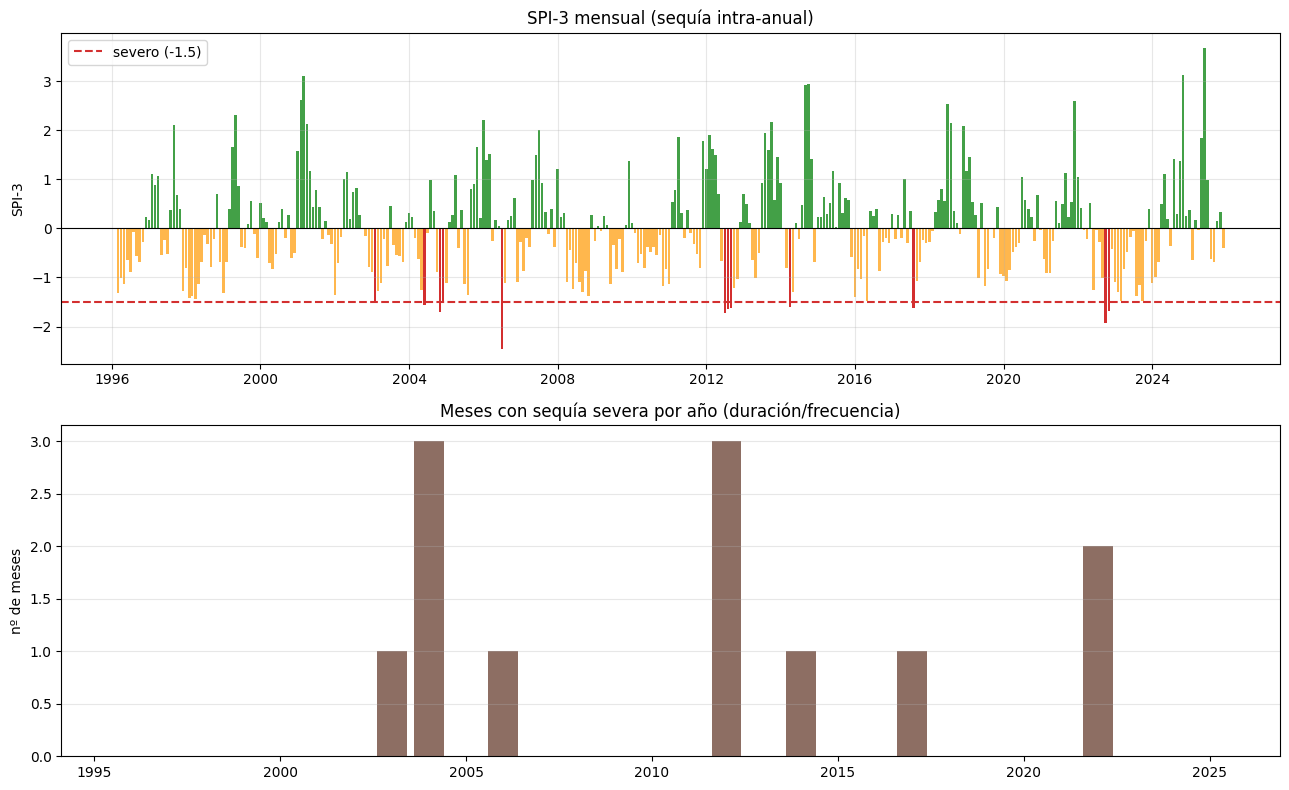

In [9]:
# ============================================================
# M5.1 SPI-3 mensual, eventos severos y duración
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def precipitacion_mensual(coleccion, anios):
    """Precipitación mensual acumulada media del AOI -> Serie pandas."""
    imgs, nombres = [], []
    for y in anios:
        for m in MESES:
            i0 = f"{y}-{m:02d}-01"
            i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
            imgs.append(coleccion.filterDate(i0, i1).sum())
            nombres.append(f"{y}-{m:02d}")
    d = reducir_bandas(imgs, nombres, ESCALAS["clima"], tam=12)
    serie = pd.Series(
        {pd.Timestamp(k): v for k, v in d.items() if v is not None}
    ).sort_index()
    return serie


def spi_estandarizado(p_mes, escala=3):
    """SPI simplificado: anomalía estandarizada de la suma móvil de `escala` meses.

    Devuelve (p_escala, spi). Si la std mensual es 0 (poco frecuente pero posible
    en zonas muy áridas), se reemplaza por NaN para no generar `inf`.
    """
    p_esc = p_mes.rolling(escala).sum()
    media_m = p_esc.groupby(p_esc.index.month).mean()
    std_m = p_esc.groupby(p_esc.index.month).std().replace(0, np.nan)
    spi = (p_esc - p_esc.index.month.map(media_m)) / p_esc.index.month.map(std_m)
    return p_esc, spi


def max_racha(mask):
    """Máxima racha consecutiva de True."""
    racha = mejor = 0
    for v in mask:
        racha = racha + 1 if bool(v) else 0
        mejor = max(mejor, racha)
    return mejor


# --- Serie mensual de precipitación -----------------------------------------
anios_clim = list(ANIOS_COMPLETOS)
p_mes = precipitacion_mensual(precip, anios_clim)
print(f"Serie de precipitación mensual: {len(p_mes)} meses "
      f"({p_mes.index.min().date()} → {p_mes.index.max().date()})")

# --- SPI-3 -------------------------------------------------------------------
p3, spi3 = spi_estandarizado(p_mes, escala=3)

df_spi = pd.DataFrame({"precip_mm": p_mes, "p3_mm": p3, "spi3": spi3}).dropna()
df_spi["severo"] = df_spi["spi3"] <= UMBRALES["spi_severo"]
df_spi["anio"] = df_spi.index.year
df_spi["mes"] = df_spi.index.month

display(df_spi.round(2).head(10))

# --- Métricas por dimensión --------------------------------------------------
peor_spi = df_spi["spi3"].min()
por_anio = df_spi.groupby("anio").agg(
    spi_min=("spi3", "min"),
    meses_severos=("severo", "sum"),
)
por_anio["anio_sequia"] = por_anio["meses_severos"] > 0
rachas = [max_racha(g["severo"]) for _, g in df_spi.groupby("anio")]

print(f"\nIntensidad: SPI-3 mínimo histórico = {peor_spi:.2f}")
print(f"Frecuencia: {int(por_anio['anio_sequia'].sum())} de {len(por_anio)} años "
      f"con sequía severa ({100 * por_anio['anio_sequia'].mean():.0f}%)")
print(f"Duración: máxima racha de meses severos = {max(rachas)} meses")

meses_criticos = (
    df_spi[df_spi["severo"]]
    .groupby("mes").size().sort_values(ascending=False).head(3)
)
print("Estacionalidad: meses con más sequías severas:",
      [(MESES_ES[m - 1], int(n)) for m, n in meses_criticos.items()])

# --- Gráficos ----------------------------------------------------------------
fig, ejes = plt.subplots(2, 1, figsize=(13, 8))

colores = np.where(df_spi["spi3"] <= UMBRALES["spi_severo"], "#d32f2f",
                   np.where(df_spi["spi3"] < 0, "#ffb74d", "#43a047"))
ejes[0].bar(df_spi.index, df_spi["spi3"], width=25, color=colores)
ejes[0].axhline(UMBRALES["spi_severo"], color="#d32f2f", ls="--",
                label=f"severo ({UMBRALES['spi_severo']})")
ejes[0].axhline(0, color="black", lw=0.8)
ejes[0].set_title("SPI-3 mensual (sequía intra-anual)")
ejes[0].set_ylabel("SPI-3")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

ejes[1].bar(por_anio.index, por_anio["meses_severos"], color="#8d6e63")
ejes[1].set_title("Meses con sequía severa por año (duración/frecuencia)")
ejes[1].set_ylabel("nº de meses")
ejes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# M6.1 Fuentes climáticas integradas: ETo y Temperatura
# ============================================================
# - Precipitación: CHIRPS (ya cargada en M5.0 como `precip`)
# - ETo ..........: ERA5-Land `potential_evaporation_sum` (m/día, signo negativo)
# - Temperatura ..: ERA5-Land `temperature_2m` (K)
# ERA5-Land: ~9 km, 1950–presente, diario.

era5 = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")


def _agregar_mensual(coleccion, banda, anios, operador="mean", escala=1.0, offset=0.0):
    """Agrega una colección diaria a serie mensual (media o suma)."""
    imgs, nombres = [], []
    for y in anios:
        for m in MESES:
            i0 = f"{y}-{m:02d}-01"
            i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
            sub = coleccion.filterDate(i0, i1).select(banda)
            img = sub.sum() if operador == "sum" else sub.mean()
            imgs.append(ee.Image(img).multiply(escala).add(offset).rename(banda))
            nombres.append(f"{y}-{m:02d}")
    d = reducir_bandas(imgs, nombres, ESCALAS["clima"], tam=12)
    return pd.Series(
        {pd.Timestamp(k): v for k, v in d.items() if v is not None}
    ).sort_index()


anios_clim = list(ANIOS_COMPLETOS)
print(f"Calculando ETo y T° mensual para {len(anios_clim)} años "
      f"(puede tardar 2–4 min)...")

# ETo (mm/mes): ERA5 trae el flujo como negativo -> se multiplica por -1000
eto_mes = _agregar_mensual(
    era5, "potential_evaporation_sum", anios_clim,
    operador="sum", escala=-1000.0
).rename("eto_mm")

# Temperatura media mensual (°C)
t_mes = _agregar_mensual(
    era5, "temperature_2m", anios_clim,
    operador="mean", escala=1.0, offset=-273.15
).rename("t_c")

# Precipitación mensual (ya la tienes en M5.0)
p_mes_ch = precipitacion_mensual(precip, anios_clim).rename("p_mm")

# Un único DataFrame alineado mes a mes
df_bh = pd.concat([p_mes_ch, eto_mes, t_mes], axis=1).dropna()
df_bh["balance"] = df_bh["p_mm"] - df_bh["eto_mm"]

print(f"Balance hídrico mensual construido: {len(df_bh)} meses")
print(df_bh.describe().round(1).loc[["mean", "min", "max"]])
display(df_bh.head())

Calculando ETo y T° mensual para 30 años (puede tardar 2–4 min)...
Balance hídrico mensual construido: 360 meses
       p_mm  eto_mm   t_c  balance
mean   22.2   144.1   9.0   -121.9
min     0.0    76.6   1.6   -209.1
max   195.6   222.4  14.1     46.2


,p_mm,eto_mm,t_c,balance
1996-01-01,51.704231,177.357359,10.952329,-125.653129
1996-02-01,46.090708,159.069204,10.817141,-112.978496
1996-03-01,14.860077,163.391350,10.379097,-148.531273
1996-04-01,3.342240,140.010398,10.265787,-136.668158
1996-05-01,1.830169,108.890431,6.897719,-107.060262


Índice de aridez medio (1996–2025): 0.16  →  Árido
Mann-Kendall: z = -0.46 · p = 0.643
Pendiente de Sen: -0.0002 /año
→ Sin tendencia significativa (p ≥ 0.05)


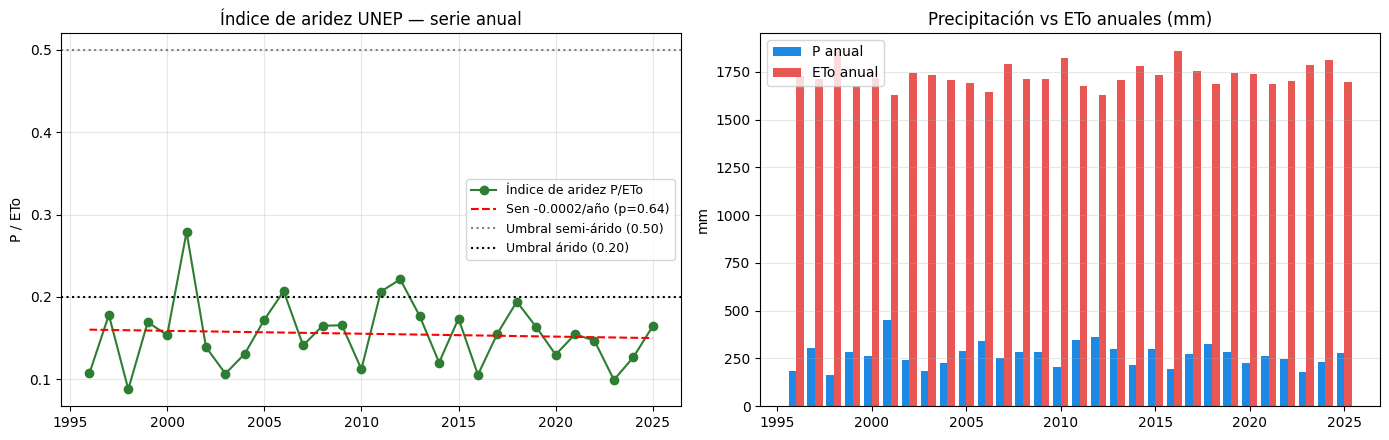

,aridez_P_ETo,clase
2011,0.21,Semi-árido
2012,0.22,Semi-árido
2013,0.18,Árido
2014,0.12,Árido
2015,0.17,Árido
2016,0.11,Árido
2017,0.16,Árido
2018,0.19,Árido
2019,0.16,Árido
2020,0.13,Árido


In [17]:
# ============================================================
# M6.4 Índice de aridez UNEP (P/ETo) + tendencia temporal
# ============================================================
aridez = por_anio_bh["p_anual_mm"] / por_anio_bh["eto_anual_mm"]
aridez.name = "aridez_P_ETo"

# Clasificación UNEP
def clasificar_unep(ai):
    if ai < 0.03:   return "Hiper-árido"
    if ai < 0.20:   return "Árido"
    if ai < 0.50:   return "Semi-árido"
    if ai < 0.65:   return "Sub-húmedo seco"
    return "Húmedo"

clase_media = clasificar_unep(aridez.mean())
print(f"Índice de aridez medio ({aridez.index.min()}–{aridez.index.max()}): "
      f"{aridez.mean():.2f}  →  {clase_media}")

# Tendencia (MK + Sen reutilizados de M5.6)
z, pval, tau = mann_kendall(aridez.values)
slope = sen_slope(aridez.values)
print(f"Mann-Kendall: z = {z:.2f} · p = {pval:.3f}")
print(f"Pendiente de Sen: {slope:+.4f} /año")
if pval < 0.05:
    sentido = "Se está volviendo MÁS ÁRIDO" if slope < 0 else "Se está volviendo MENOS ÁRIDO"
    print(f"→ Tendencia significativa: {sentido}")
else:
    print("→ Sin tendencia significativa (p ≥ 0.05)")

# --- Gráfico ----------------------------------------------------------------
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: serie del índice con línea de tendencia
recta = np.polyval(np.polyfit(aridez.index.astype(int), aridez.values, 1),
                   aridez.index.astype(int))
ejes[0].plot(aridez.index, aridez.values, "o-", color="#2e7d32",
             label="Índice de aridez P/ETo")
ejes[0].plot(aridez.index, recta, "--", color="red",
             label=f"Sen {slope:+.4f}/año (p={pval:.2f})")
ejes[0].axhline(0.50, color="gray", ls=":", label="Umbral semi-árido (0.50)")
ejes[0].axhline(0.20, color="black", ls=":", label="Umbral árido (0.20)")
ejes[0].set_title("Índice de aridez UNEP — serie anual")
ejes[0].set_ylabel("P / ETo")
ejes[0].legend(fontsize=9)
ejes[0].grid(alpha=0.3)

# Panel 2: reparto anual en barras apiladas (P y ETo superpuestos)
ancho = 0.4
ejes[1].bar(por_anio_bh.index - ancho/2, por_anio_bh["p_anual_mm"], ancho,
            color="#1e88e5", label="P anual")
ejes[1].bar(por_anio_bh.index + ancho/2, por_anio_bh["eto_anual_mm"], ancho,
            color="#e53935", alpha=0.85, label="ETo anual")
ejes[1].set_title("Precipitación vs ETo anuales (mm)")
ejes[1].set_ylabel("mm")
ejes[1].legend()
ejes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

display(pd.DataFrame({"aridez_P_ETo": aridez.round(2),
                      "clase": aridez.apply(clasificar_unep)}).tail(15))

Meses con sequía severa según SPI-3: 12
Meses con sequía severa según SPEI-3: 20
Meses donde SPEI detecta sequía pero SPI no: 19 → sequías de origen TÉRMICO (calor, no falta de lluvia)


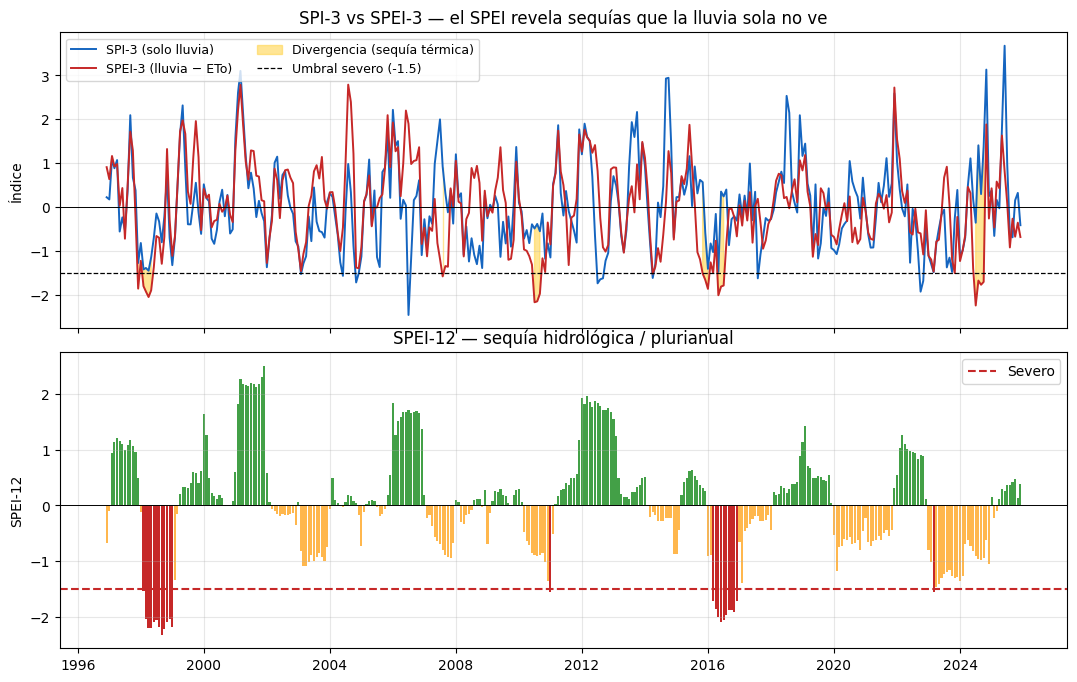


Top 10 meses más secos según SPEI-3:


,SPI-3,SPEI-3,SPEI-12,divergencia
2024-07-01,-0.35,-2.24,-0.91,True
2010-07-01,-0.48,-2.16,-0.88,True
2010-08-01,-0.38,-2.14,-0.90,True
1998-04-01,-1.44,-2.04,-2.19,True
2016-05-01,-1.47,-2.00,-2.00,True
2010-09-01,-0.55,-1.97,-0.89,True
1998-03-01,-1.38,-1.92,-2.03,True
1998-05-01,-1.14,-1.89,-2.20,True
2016-01-01,-1.40,-1.86,-0.91,True
1997-12-01,-1.27,-1.85,0.50,True


In [18]:
# ============================================================
# M6.5 SPEI-3 / SPEI-12 vs SPI-3 (comparación directa)
# ============================================================

def spei_estandarizado(balance_mensual, escala=3):
    """Análogo a spi_estandarizado pero sobre P−ETo."""
    b_esc = balance_mensual.rolling(escala).sum()
    media_m = b_esc.groupby(b_esc.index.month).mean()
    std_m = b_esc.groupby(b_esc.index.month).std().replace(0, np.nan)
    spei = (b_esc - b_esc.index.month.map(media_m)) / b_esc.index.month.map(std_m)
    return b_esc, spei


# --- Cálculo ----------------------------------------------------------------
# SPI-3 (ya definido en M5.1, se recalcula aquí por claridad)
_, spi3_rec = spi_estandarizado(p_mes_ch, escala=3)
# SPEI-3 y SPEI-12 sobre el balance P−ETo
_, spei3 = spei_estandarizado(df_bh["balance"], escala=3)
_, spei12 = spei_estandarizado(df_bh["balance"], escala=12)

df_comp = pd.DataFrame({
    "SPI-3": spi3_rec, "SPEI-3": spei3, "SPEI-12": spei12
}).dropna()
df_comp["severo_SPI"] = df_comp["SPI-3"] <= UMBRALES["spi_severo"]
df_comp["severo_SPEI"] = df_comp["SPEI-3"] <= UMBRALES["spi_severo"]
df_comp["divergencia"] = df_comp["severo_SPEI"] & ~df_comp["severo_SPI"]

print("Meses con sequía severa según SPI-3:", int(df_comp["severo_SPI"].sum()))
print("Meses con sequía severa según SPEI-3:", int(df_comp["severo_SPEI"].sum()))
print("Meses donde SPEI detecta sequía pero SPI no:",
      int(df_comp["divergencia"].sum()),
      "→ sequías de origen TÉRMICO (calor, no falta de lluvia)")

# --- Gráfico combinado ------------------------------------------------------
fig, ejes = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                         gridspec_kw={"hspace": 0.08})

# Panel superior: SPI-3 y SPEI-3 en el mismo eje
ejes[0].plot(df_comp.index, df_comp["SPI-3"], color="#1565c0",
             lw=1.4, label="SPI-3 (solo lluvia)")
ejes[0].plot(df_comp.index, df_comp["SPEI-3"], color="#c62828",
             lw=1.4, label="SPEI-3 (lluvia − ETo)")
ejes[0].fill_between(df_comp.index, df_comp["SPI-3"], df_comp["SPEI-3"],
                     where=df_comp["divergencia"].values,
                     color="#ffd54f", alpha=0.6,
                     label="Divergencia (sequía térmica)")
ejes[0].axhline(UMBRALES["spi_severo"], color="black", ls="--", lw=0.9,
                label=f"Umbral severo ({UMBRALES['spi_severo']})")
ejes[0].axhline(0, color="black", lw=0.7)
ejes[0].set_ylabel("Índice")
ejes[0].set_title("SPI-3 vs SPEI-3 — el SPEI revela sequías que la lluvia sola no ve")
ejes[0].legend(ncol=2, fontsize=9)
ejes[0].grid(alpha=0.3)

# Panel inferior: SPEI-12 (sequía plurianual)
colores = np.where(df_comp["SPEI-12"] <= UMBRALES["spi_severo"],
                   "#c62828", np.where(df_comp["SPEI-12"] < 0,
                                       "#ffb74d", "#43a047"))
ejes[1].bar(df_comp.index, df_comp["SPEI-12"], width=25, color=colores)
ejes[1].axhline(UMBRALES["spi_severo"], color="#c62828", ls="--",
                label="Severo")
ejes[1].axhline(0, color="black", lw=0.7)
ejes[1].set_ylabel("SPEI-12")
ejes[1].set_title("SPEI-12 — sequía hidrológica / plurianual")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Ranking de sequías combinadas
top_sequias = df_comp.sort_values("SPEI-3").head(10)
print("\nTop 10 meses más secos según SPEI-3:")
display(top_sequias[["SPI-3", "SPEI-3", "SPEI-12", "divergencia"]].round(2))

In [21]:
# ============================================================
# M6.6 Mapa del balance hídrico y aridez por píxel (recortado al AOI)
# ============================================================
# Años: todos los de ANIOS_COMPLETOS desde 2000 (ERA5-Land con mejor calidad)
# → El mapa muestra el PROMEDIO del período, no un año concreto.
anios_mapa = [y for y in ANIOS_COMPLETOS if y >= 2000]
print(f"Período del promedio: {anios_mapa[0]} – {anios_mapa[-1]} "
      f"({len(anios_mapa)} años)")

# --- Precipitación media anual por píxel (CHIRPS) ----------------------------
pp_pix = (ee.ImageCollection([
              precip.filterDate(f"{y}-01-01", f"{y+1}-01-01")
                    .sum().rename("p")
              for y in anios_mapa
          ])
          .mean()
          .clip(roi)                      # <-- recorte al GeoJSON
          .rename("p_anual"))

# --- ETo media anual por píxel (ERA5-Land) -----------------------------------
def _eto_anual(y):
    return (era5.filterDate(f"{y}-01-01", f"{y+1}-01-01")
            .select("potential_evaporation_sum")
            .sum().multiply(-1000).rename("eto"))

eto_pix = (ee.ImageCollection([_eto_anual(y).rename("eto")
                               for y in anios_mapa])
           .mean()
           .clip(roi)                     # <-- recorte al GeoJSON
           .rename("eto_anual"))

# --- Balance y aridez (ya heredan el clip) -----------------------------------
balance_pix = pp_pix.subtract(eto_pix).rename("balance")
aridez_pix  = pp_pix.divide(eto_pix).rename("aridez")

# --- Estadísticas medias dentro del AOI (para mostrar en texto) --------------
stats = reducir_bandas(
    [pp_pix, eto_pix, balance_pix, aridez_pix],
    ["p_anual", "eto_anual", "balance", "aridez"],
    ESCALAS["clima"],
)
print(f"P media anual .......... {stats['p_anual']:.0f} mm")
print(f"ETo media anual ........ {stats['eto_anual']:.0f} mm")
print(f"Balance P−ETo .......... {stats['balance']:.0f} mm/año")
print(f"Índice de aridez P/ETo . {stats['aridez']:.2f}")

def _clasificar(ai):
    if ai < 0.03:  return "Hiper-árido"
    if ai < 0.20:  return "Árido"
    if ai < 0.50:  return "Semi-árido"
    if ai < 0.65:  return "Sub-húmedo seco"
    return "Sub-húmedo"

print(f"Clase UNEP ............. {_clasificar(stats['aridez'])}")

# --- Visualización -----------------------------------------------------------
Map_m6 = geemap.Map()
Map_m6.centerObject(roi, ZONA["zoom"])
Map_m6.add_basemap("HYBRID")

vis_aridez = {
    "min": 0.0, "max": 1.0,
    "palette": ["#8b0000", "#d32f2f", "#f57c00", "#fbc02d",
                "#aed581", "#43a047", "#1b5e20"]
}
vis_balance = {
    "min": -1500, "max": 500,
    "palette": ["#8b0000", "#c62828", "#ef6c00", "#fbc02d",
                "#aed581", "#43a047"]
}

Map_m6.addLayer(aridez_pix, vis_aridez,
                f"Índice de aridez P/ETo ({anios_mapa[0]}–{anios_mapa[-1]})")
Map_m6.addLayer(balance_pix, vis_balance,
                "Balance P−ETo (mm/año)", shown=False)   # apagada por defecto
Map_m6.addLayer(borde_aoi(color="FF0000", ancho=2), {}, "AOI (GeoJSON)")

Map_m6.add_colorbar(
    vis_aridez,
    label="P/ETo  (<0.2 árido · 0.2–0.5 semi-árido · >0.5 sub-húmedo)",
    orientation="horizontal", position="bottomright",
    layer_name=f"Índice de aridez P/ETo ({anios_mapa[0]}–{anios_mapa[-1]})"
)
Map_m6

Período del promedio: 2000 – 2025 (26 años)
P media anual .......... 271 mm
ETo media anual ........ 1727 mm
Balance P−ETo .......... -1456 mm/año
Índice de aridez P/ETo . 0.16
Clase UNEP ............. Árido


Map(center=[-19.436538457151876, -67.61413826547425], controls=(WidgetControl(options=['position', 'transparen…

## Interpretación de M5
* **Serie SPI-3:** cada episodio rojo es una sequía intra-anual (clásica en el Altiplano: verano
  fallido entre dic–mar). La *duración* (racha) y la *intensidad* (mínimo) determinan pérdidas.
* **Mapa de frecuencia:** las zonas con más años secos (rojo) son las que priorizan
  **riego inteligente, cosecha de agua y seguros agrícolas** (PROSUCO) y estaciones CLIMBAT.
* La frecuencia por píxel permite zonificar: ¿se seca toda la zona o solo ciertas altitudes/orientaciones?

**Preguntas guía**
1. ¿Los años rojos de la serie corresponden a sequías recordadas por los observadores?
2. ¿Qué partes del territorio se secan siempre y cuáles solo a veces?
3. ¿El SPI negativo coincide con el año de menor NDVI (M7)? (cruzar resultados)

## Cierre: checklist del modulo

- [ ] Parte base ejecutada (instalacion, autenticacion GEE, CONFIG, AOI del GeoJSON).
- [ ] Mapa(s) revisados contra el borde rojo del AOI (el GeoJSON siempre manda).
- [ ] Serie/tabla leidas + interpretacion contrastada con saber local (Yapuchiri/PACHASOL).
- [ ] Periodo y dataset anotados junto a cada numero (p. ej. `CHIRPS 1981-2025`).

### Como cambiar de satelite o de anos (patron en todos los modulos)

```python
FECHA_INICIO = "1996-01-01"  # en la celda CONFIG: ventana analitica
FECHA_FIN = "2026-12-31"
# --- Primario (default) ---
precip = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
# --- Alternativas: comentar la primaria y descomentar la elegida ---
# precip = ee.ImageCollection("NASA/GPM_L3/IMERG_V06")
# Cada alternativa indica resolucion, periodo y para que sirve.
```
